In [1]:
%matplotlib widget


In [2]:
import h5py
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.filters import frangi
from matplotlib.widgets import Button
import ipywidgets as widgets
from IPython.display import display
import csv
from pathlib import Path
import h5py
from scipy.interpolate import griddata
from scipy.interpolate import splprep, splev, interp1d, PchipInterpolator
from scipy.ndimage import map_coordinates
from scipy.interpolate import PchipInterpolator
from matplotlib.ticker import FuncFormatter

In [3]:
#image_file = h5py.File('plot_file_20260723Julh07m1784788016s','r')
#sheet_cube = image_file['sheet_cube'][:]
#sheet_cube = np.flip(sheet_cube)
#sheet_cube = np.flip(sheet_cube, axis=1)

slice_file = h5py.File('mgn_ng_1024.hdf5','r')
raw_data = slice_file['cube_display']
coords_file = h5py.File('t_h_plot_coords_20221108152301','r')
coords_from_file = coords_file['x_coords_all']

slice_data = raw_data[550:675,0:550,145:270]

In [4]:
x_coords_all = coords_from_file
x_min = min(x_coords_all)
x_max = max(x_coords_all)

dict_group_load = coords_file['coords_dict']
dict_group_keys = dict_group_load.keys()


In [5]:
# ============================================================
# CONFIGURATION
# Establishing constants, 
# ============================================================

CADENCE_SECONDS = 24.0

DISTANCE_SUN_M = 151151239792.45
PLATE_SCALE_ARCSEC = 0.6

# Solar-surface reference, in cropped-image coordinates
SOLAR_SURFACE_POINT = np.array([485.0, 3.0])

FLARE_CUTOFF_X = 409.0

N_PATH_SAMPLES = 300
DENSE_SAMPLES = 2000
SLIT_WIDTH = 5

DIFFERENCE_INTERVAL = 3

# Available: original, background, difference,
# normalized, percentage
ENHANCEMENT_METHOD = "normalized"

# ============================================================
# IMAGE PREPARATION
# ============================================================

# Original slice_data shape: (y, x, frames)
# Working shape: (frames, x, y)

image_data = np.transpose(
    np.asarray(slice_data, dtype=float),
    (2, 1, 0)
)

n_frames, nx, ny = image_data.shape

time_seconds = np.arange(n_frames) * CADENCE_SECONDS

# Angular pixel scale converted to projected km
SOLAR_KM_PER_PIXEL = (
    DISTANCE_SUN_M
    * np.tan(np.deg2rad(PLATE_SCALE_ARCSEC / 3600.0))
    / 1000.0
)

print("Image shape:", image_data.shape)
print(f"Cadence: {CADENCE_SECONDS:g} s")
print(f"Image scale: {SOLAR_KM_PER_PIXEL:.3f} km/pixel")
print(f"Duration: {time_seconds[-1]:.1f} s")
print("Solar reference:", SOLAR_SURFACE_POINT)

Image shape: (125, 550, 125)
Cadence: 24 s
Image scale: 439.681 km/pixel
Duration: 2976.0 s
Solar reference: [485.   3.]


In [6]:
def cumulative_arc_length(points):
    points = np.asarray(points, dtype=float)

    return np.r_[
        0.0,
        np.cumsum(
            np.linalg.norm(
                np.diff(points, axis=0),
                axis=1
            )
        )
    ]


def resample_path(points, n_samples=N_PATH_SAMPLES):
    points = np.asarray(points, dtype=float)

    arc = cumulative_arc_length(points)
    arc, unique_idx = np.unique(arc, return_index=True)
    points = points[unique_idx]

    if len(arc) < 2 or arc[-1] <= 0:
        raise ValueError("Insufficient path length.")

    target = np.linspace(0, arc[-1], n_samples)

    return np.column_stack([
        np.interp(target, arc, points[:, 0]),
        np.interp(target, arc, points[:, 1])
    ])


def fit_path(points, cutoff=FLARE_CUTOFF_X):
    points = np.asarray(points, dtype=float)
    points = points[np.isfinite(points).all(axis=1)]

    if len(points) < 2:
        raise ValueError("Too few valid points.")

    # Orient from the flare side toward the outward end
    if points[0, 0] < points[-1, 0]:
        points = points[::-1]

    outside = np.flatnonzero(points[:, 0] <= cutoff)

    if len(outside) < 2:
        raise ValueError(
            "Not enough points outside the flare cutoff."
        )

    # Include one point on the flare side for interpolation
    first = outside[0]
    selected = points[max(0, first - 1):]

    # Remove consecutive duplicate points
    steps = np.linalg.norm(
        np.diff(selected, axis=0),
        axis=1
    )

    selected = selected[
        np.r_[True, steps > 1e-10]
    ]

    if len(selected) < 2:
        raise ValueError("Insufficient distinct points.")

    if np.all(np.diff(selected[:, 0]) < 0):
        # Monotonic x: shape-preserving interpolation
        x_dense = np.linspace(
            selected[0, 0],
            selected[-1, 0],
            DENSE_SAMPLES
        )

        spline = PchipInterpolator(
            selected[::-1, 0],
            selected[::-1, 1]
        )

        y_dense = spline(x_dense)

    else:
        # Nonmonotonic x: parametric spline
        arc = cumulative_arc_length(selected)
        u = arc / arc[-1]

        tck, _ = splprep(
            [selected[:, 0], selected[:, 1]],
            u=u,
            s=0,
            k=min(3, len(selected) - 1)
        )

        x_dense, y_dense = splev(
            np.linspace(0, 1, DENSE_SAMPLES),
            tck
        )

    dense = np.column_stack([x_dense, y_dense])

    outside_dense = np.flatnonzero(
        dense[:, 0] <= cutoff
    )

    if len(outside_dense) == 0:
        raise ValueError("Curve never reaches the cutoff.")

    i = outside_dense[0]

    if i > 0:
        a, b = dense[i - 1], dense[i]

        if abs(b[0] - a[0]) > 1e-12:
            fraction = (cutoff - a[0]) / (b[0] - a[0])
        else:
            fraction = 1.0

        boundary = a + fraction * (b - a)
        trimmed = np.vstack([boundary, dense[i:]])
    else:
        trimmed = dense[i:]

    # Stop at first re-entry into the flare region
    reentry = np.flatnonzero(
        trimmed[1:, 0] > cutoff + 1e-8
    )

    if len(reentry):
        trimmed = trimmed[:reentry[0] + 1]

    return resample_path(trimmed)


# ============================================================
# FIT ALL MEASURED PATHS
# ============================================================

measured_frames = sorted(
    int(key[:-2])
    for key in dict_group_load
    if key.endswith("_x")
    and key[:-2].isdigit()
    and f"{key[:-2]}_y" in dict_group_load
)

if len(measured_frames) < 2:
    raise ValueError("At least two measured frames required.")

if measured_frames[0] < 0 or measured_frames[-1] >= n_frames:
    raise ValueError("Measured frame outside image sequence.")

fitted_paths = []

for frame in measured_frames:
    x = np.asarray(
        dict_group_load[f"{frame}_x"],
        dtype=float
    ).ravel()

    y = np.asarray(
        dict_group_load[f"{frame}_y"],
        dtype=float
    ).ravel()

    if len(x) != len(y):
        raise ValueError(
            f"Frame {frame}: x and y lengths differ."
        )

    fitted_paths.append(
        fit_path(np.column_stack([x, y]))
    )

fitted_paths = np.asarray(fitted_paths)

# Interpolate between manually measured frames
path_interpolator = interp1d(
    measured_frames,
    fitted_paths,
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value=(fitted_paths[0], fitted_paths[-1])
)

all_paths = path_interpolator(
    np.arange(n_frames)
)

print("Measured paths:", fitted_paths.shape)
print("Interpolated paths:", all_paths.shape)

Measured paths: (41, 300, 2)
Interpolated paths: (125, 300, 2)


In [7]:
def extract_profile(image, path, slit_width=SLIT_WIDTH):
    x = path[:, 0]
    y = path[:, 1]

    dx = np.gradient(x)
    dy = np.gradient(y)

    magnitude = np.maximum(
        np.hypot(dx, dy),
        1e-12
    )

    normal_x = -dy / magnitude
    normal_y = dx / magnitude

    offsets = np.linspace(
        -(slit_width - 1) / 2,
        (slit_width - 1) / 2,
        slit_width
    )

    samples = []

    for offset in offsets:
        sx = x + offset * normal_x
        sy = y + offset * normal_y

        values = map_coordinates(
            image,
            [sx, sy],
            order=1,
            mode="constant",
            cval=np.nan
        )

        # Exclude flare-region and out-of-image samples
        valid = (
            (sx <= FLARE_CUTOFF_X) &
            (sx >= 0) & (sx <= nx - 1) &
            (sy >= 0) & (sy <= ny - 1)
        )

        values[~valid] = np.nan
        samples.append(values)

    samples = np.asarray(samples)

    counts = np.isfinite(samples).sum(axis=0)

    profile = np.full(len(path), np.nan)

    np.divide(
        np.nansum(samples, axis=0),
        counts,
        out=profile,
        where=counts > 0
    )

    return profile


# ============================================================
# EXTRACT INTENSITY ALONG EACH CURVE
# ============================================================

time_distance = np.asarray([
    extract_profile(image_data[i], all_paths[i])
    for i in range(n_frames)
])

# Cumulative arc distance along fitted curves
all_distances = np.asarray([
    cumulative_arc_length(path) * SOLAR_KM_PER_PIXEL
    for path in all_paths
])

curve_lengths_km = all_distances[:, -1]

# ============================================================
# SOLAR SURFACE OFFSETS
# ============================================================

# Path sample zero is the base near the flare cutoff
base_points = all_paths[:, 0, :]

surface_offsets_km = (
    np.linalg.norm(
        base_points - SOLAR_SURFACE_POINT,
        axis=1
    )
    * SOLAR_KM_PER_PIXEL
)

# Physical distance of every sample from reference point
all_distances_surface = (
    all_distances + surface_offsets_km[:, None]
)

print("Solar-surface offset statistics:")
print(f"Min:  {surface_offsets_km.min():,.2f} km")
print(f"Mean: {surface_offsets_km.mean():,.2f} km")
print(f"Max:  {surface_offsets_km.max():,.2f} km")

# ============================================================
# COMMON SOLAR-REFERENCED DISTANCE GRID
# ============================================================

# Use intersection of all frames' distance ranges.
# This avoids extrapolating intensity into unobserved regions.

distance_min = np.max(
    all_distances_surface[:, 0]
)

distance_max = np.min(
    all_distances_surface[:, -1]
)

if distance_max <= distance_min:
    raise ValueError(
        "No common solar-referenced distance range "
        "exists across all frames."
    )

distance_grid_surface = np.linspace(
    distance_min,
    distance_max,
    N_PATH_SAMPLES
)

ridge_km_per_pixel = float(
    np.mean(np.diff(distance_grid_surface))
)

# ============================================================
# RESAMPLE INTENSITY ONTO COMMON DISTANCE GRID
# ============================================================

time_distance_km = np.full(
    (n_frames, N_PATH_SAMPLES),
    np.nan
)

for frame in range(n_frames):
    distances = all_distances_surface[frame]
    intensity = time_distance[frame]

    valid = np.isfinite(intensity)

    # Interpolate only within contiguous valid segments
    starts = np.flatnonzero(
        valid & ~np.r_[False, valid[:-1]]
    )

    ends = np.flatnonzero(
        valid & ~np.r_[valid[1:], False]
    ) + 1

    for start, end in zip(starts, ends):
        if end - start < 2:
            continue

        segment_d, unique_idx = np.unique(
            distances[start:end],
            return_index=True
        )

        segment_i = intensity[start:end][unique_idx]

        if len(segment_d) < 2:
            continue

        mask = (
            (distance_grid_surface >= segment_d[0]) &
            (distance_grid_surface <= segment_d[-1])
        )

        time_distance_km[frame, mask] = np.interp(
            distance_grid_surface[mask],
            segment_d,
            segment_i
        )

# Also retain a relative distance axis for comparison
distance_grid = (
    distance_grid_surface - distance_grid_surface[0]
)

print()
print("Time-height image:", time_distance_km.shape)
print(f"Distance grid minimum: {distance_min:,.1f} km")
print(f"Distance grid maximum: {distance_max:,.1f} km")
print(f"Vertical pixel scale: {ridge_km_per_pixel:.3f} km/pixel")

Solar-surface offset statistics:
Min:  33,958.96 km
Mean: 34,144.33 km
Max:  34,399.40 km

Time-height image: (125, 300)
Distance grid minimum: 34,399.4 km
Distance grid maximum: 204,382.4 km
Vertical pixel scale: 568.505 km/pixel


In [8]:
def nan_gaussian(data, sigma):
    data = np.asarray(data, dtype=float)

    valid = np.isfinite(data)

    numerator = gaussian_filter(
        np.where(valid, data, 0.0),
        sigma=sigma
    )

    denominator = gaussian_filter(
        valid.astype(float),
        sigma=sigma
    )

    return np.divide(
        numerator,
        denominator,
        out=np.full_like(data, np.nan),
        where=denominator > 1e-8
    )


td = time_distance_km.copy()

original = td.copy()

background = np.nanmedian(td, axis=0)

background_subtracted = (
    td - background[None, :]
)

running_difference = np.full_like(td, np.nan)

running_difference[DIFFERENCE_INTERVAL:] = (
    td[DIFFERENCE_INTERVAL:] -
    td[:-DIFFERENCE_INTERVAL]
)

# Local background subtraction
smooth_background = nan_gaussian(
    td, sigma=(8, 12)
)

high_pass = td - smooth_background

local_std = np.nanstd(high_pass, axis=0)

positive_std = local_std[
    np.isfinite(local_std) & (local_std > 0)
]

std_floor = (
    np.percentile(positive_std, 10)
    if positive_std.size else 1.0
)

normalized = high_pass / np.maximum(
    local_std[None, :],
    max(std_floor, 1e-10)
)

positive_background = background[
    np.isfinite(background) & (background > 0)
]

background_floor = (
    np.percentile(positive_background, 5)
    if positive_background.size else 1.0
)

percentage_variation = (
    100.0 * background_subtracted /
    np.maximum(
        background[None, :],
        max(background_floor, 1e-10)
    )
)

enhanced_images = {
    "original": original,
    "background": background_subtracted,
    "difference": running_difference,
    "normalized": normalized,
    "percentage": percentage_variation
}

# Select enhancement
selected_td = enhanced_images[ENHANCEMENT_METHOD]

# Shape: (distance, time)
sheet_cube = selected_td.T.copy()

print("Selected enhancement:", ENHANCEMENT_METHOD)
print("Tracer image shape:", sheet_cube.shape)

Selected enhancement: normalized
Tracer image shape: (300, 125)


/home/chris/.local/lib/python3.10/site-packages/ipympl/backend_nbagg.py:392: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  self.figure.savefig(buf, format='png', dpi='figure')


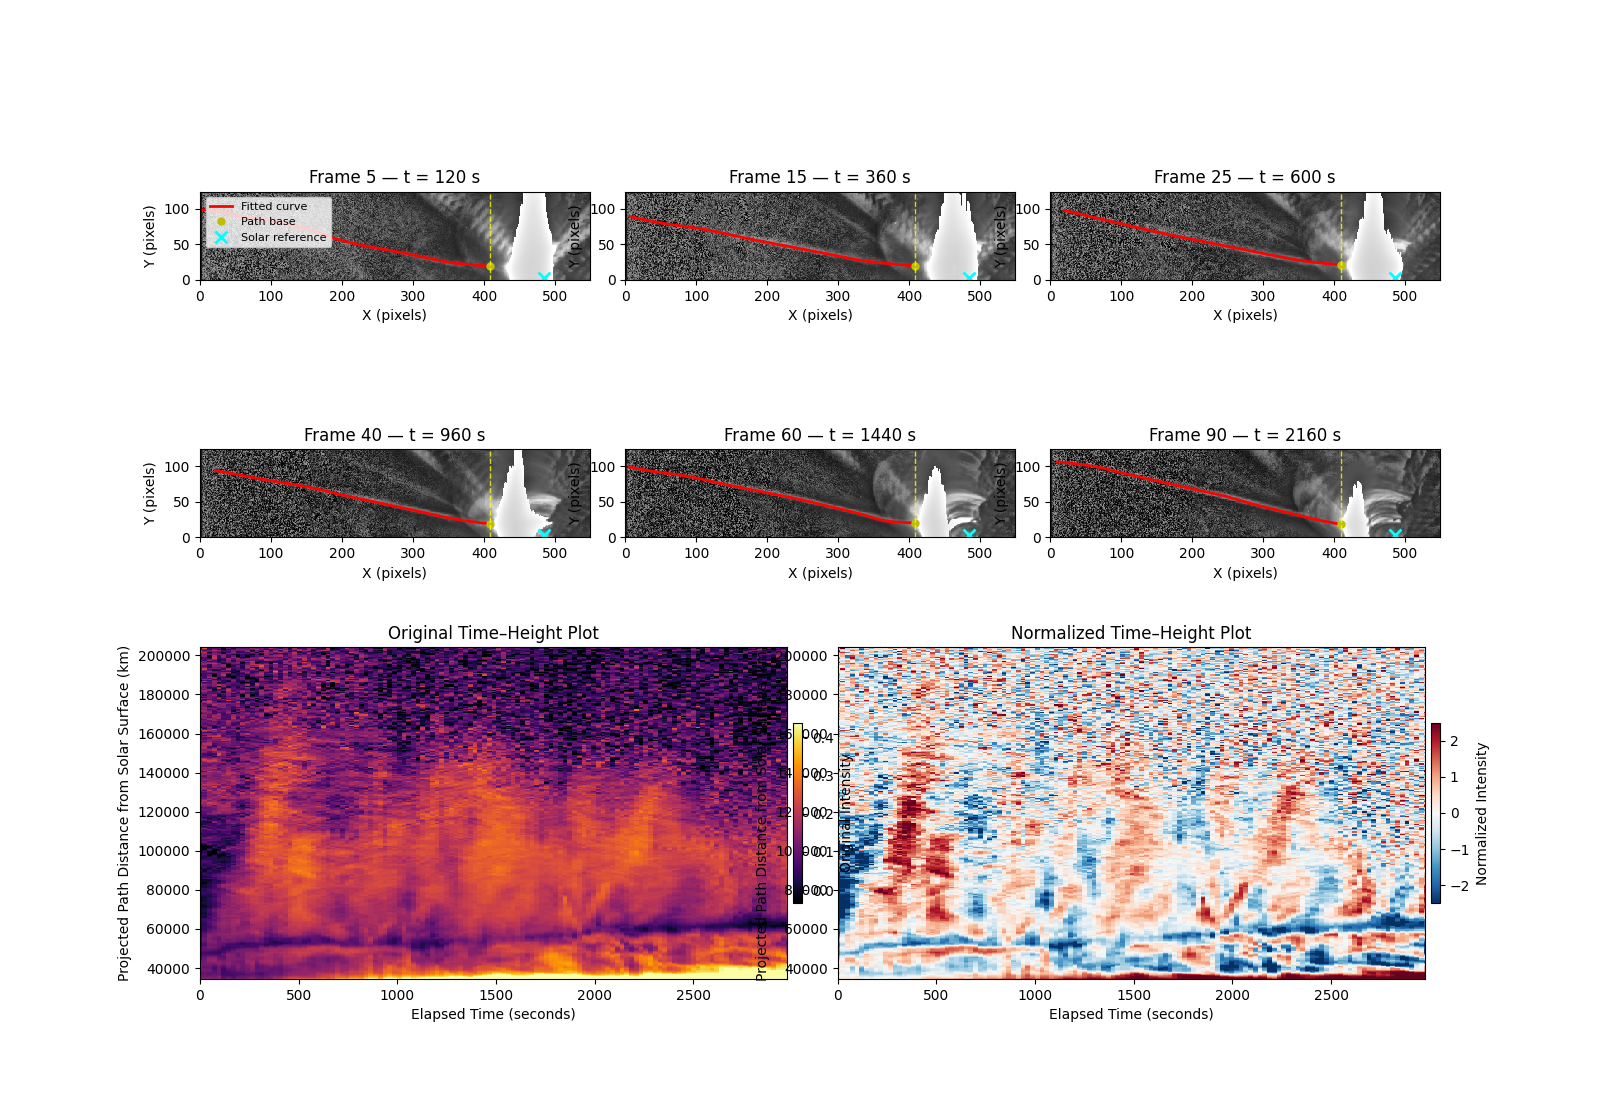

In [9]:
# ============================================================
# STEP 5 — FIT DIAGNOSTICS AND TIME-HEIGHT COMPARISON
# ============================================================

diagnostic_frames = [5, 15, 25, 40, 60, 90]

# Validate frame indices
diagnostic_frames = [
    f for f in diagnostic_frames
    if 0 <= f < n_frames
]

fig = plt.figure(figsize=(16, 11), constrained_layout=True)

gs = fig.add_gridspec(
    3, 6,
    height_ratios=[1, 1, 1.6]
)

# Shared image contrast avoids changes in apparent brightness
finite_solar = image_data[np.isfinite(image_data)]
solar_vmin, solar_vmax = np.percentile(
    finite_solar, [2, 99.5]
)

# ------------------------------------------------------------
# TOP: SIX FRAMES WITH FITTED PATHS
# ------------------------------------------------------------

for i, frame in enumerate(diagnostic_frames):
    ax = fig.add_subplot(
        gs[i // 3, (i % 3) * 2:(i % 3) * 2 + 2]
    )

    ax.imshow(
        image_data[frame].T,
        origin="lower",
        cmap="gray",
        vmin=solar_vmin,
        vmax=solar_vmax,
        interpolation="nearest"
    )

    path = all_paths[frame]

    ax.plot(
        path[:, 0],
        path[:, 1],
        color="red",
        linewidth=2,
        label="Fitted curve"
    )

    ax.plot(
        path[0, 0],
        path[0, 1],
        "yo",
        markersize=5,
        label="Path base"
    )

    ax.plot(
        SOLAR_SURFACE_POINT[0],
        SOLAR_SURFACE_POINT[1],
        marker="x",
        color="cyan",
        markersize=8,
        markeredgewidth=2,
        linestyle="None",
        label="Solar reference"
    )

    ax.axvline(
        FLARE_CUTOFF_X,
        color="yellow",
        linestyle="--",
        linewidth=1,
        alpha=0.8
    )

    ax.set_title(
        f"Frame {frame} — t = {time_seconds[frame]:.0f} s"
    )
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
    ax.set_xlim(0, nx - 1)
    ax.set_ylim(0, ny - 1)

    if i == 0:
        ax.legend(loc="upper left", fontsize=8)


# ------------------------------------------------------------
# BOTTOM: ORIGINAL AND NORMALIZED TIME-HEIGHT PLOTS
# ------------------------------------------------------------

def calibrated_extent(distance_axis, time_axis):
    dt = (
        time_axis[1] - time_axis[0]
        if len(time_axis) > 1 else 1.0
    )
    dd = (
        distance_axis[1] - distance_axis[0]
        if len(distance_axis) > 1 else 1.0
    )

    return [
        time_axis[0] - dt / 2,
        time_axis[-1] + dt / 2,
        distance_axis[0] - dd / 2,
        distance_axis[-1] + dd / 2
    ]


extent = calibrated_extent(
    distance_grid_surface,
    time_seconds
)

def plot_calibrated_panel(ax, data, title, normalized_view=False):
    finite = data[np.isfinite(data)]

    if not finite.size:
        raise ValueError(f"No finite pixels for {title}")

    if normalized_view:
        limit = max(
            np.percentile(np.abs(finite), 98),
            1e-10
        )
        vmin, vmax = -limit, limit
        cmap = "RdBu_r"
    else:
        vmin, vmax = np.percentile(finite, [2, 99])
        if vmax <= vmin:
            vmax = vmin + 1
        cmap = "inferno"

    im = ax.imshow(
        data.T,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.set_xlim(time_seconds[0], time_seconds[-1])
    ax.set_ylim(
        distance_grid_surface[0],
        distance_grid_surface[-1]
    )
    ax.set_title(title)
    ax.set_xlabel("Elapsed Time (seconds)")
    ax.set_ylabel(
        "Projected Path Distance from Solar Surface (km)"
    )

    return im


# Use the bottom two rows for full-width plots
ax_original = fig.add_subplot(gs[2, 0:3])
ax_normalized = fig.add_subplot(gs[2, 3:6])

im_original = plot_calibrated_panel(
    ax_original,
    original,
    "Original Time–Height Plot"
)

im_normalized = plot_calibrated_panel(
    ax_normalized,
    normalized,
    "Normalized Time–Height Plot",
    normalized_view=True
)

fig.colorbar(
    im_original,
    ax=ax_original,
    label="Original Intensity",
    fraction=0.015,
    pad=0.01
)

fig.colorbar(
    im_normalized,
    ax=ax_normalized,
    label="Normalized Intensity",
    fraction=0.015,
    pad=0.01
)

plt.show()

In [10]:

# ============================================================
# STEP 6 — MULTI-POINT DUAL SOLAR RIDGE TRACER
# ============================================================

class DualSolarRidgeTracer:
    """
    Interactive multi-point ridge tracer.

    Input image shape:
        (distance_pixels, time_frames)

    Features:
        - Original and normalized panels
        - Unlimited guide points
        - Curved, intensity-guided tracing
        - Exact passage through guide points
        - Adjustable tracing parameters
        - Solar-referenced distance calibration
        - Projected velocity measurements
        - Save results and figures
    """

    def __init__(
        self,
        original_image,
        normalized_image,
        distance_grid_km,
        cadence_seconds=24.0,
        max_step=8,
        corridor=20,
        curvature_weight=0.5,
        slope_weight=0.03,
        ridge_weight=2.0,
        guide_weight=0.02
    ):
        self.original_image = np.asarray(
            original_image, dtype=float
        )

        self.normalized_image = np.asarray(
            normalized_image, dtype=float
        )

        self.distance_grid = np.asarray(
            distance_grid_km, dtype=float
        )

        self.cadence = float(cadence_seconds)

        if self.original_image.shape != self.normalized_image.shape:
            raise ValueError(
                "Original and normalized images must have the same shape."
            )

        if self.original_image.ndim != 2:
            raise ValueError("Images must be 2D.")

        self.height, self.width = self.original_image.shape

        if len(self.distance_grid) != self.height:
            raise ValueError(
                "Distance grid length must equal image height."
            )

        if not np.all(np.diff(self.distance_grid) > 0):
            raise ValueError(
                "Distance grid must be strictly increasing."
            )

        if self.cadence <= 0:
            raise ValueError("Cadence must be positive.")

        self.max_step = int(max_step)
        self.corridor = int(corridor)
        self.curvature_weight = float(curvature_weight)
        self.slope_weight = float(slope_weight)
        self.ridge_weight = float(ridge_weight)
        self.guide_weight = float(guide_weight)

        self.paths = []
        self.selected_points = []

        self.score_source = "Normalized"
        self.score_image = self._prepare_score(
            self.normalized_image
        )

        self.path_artists = []
        self.selection_artists = []
        self.guide_artists = []

        self._create_interface()

    # ========================================================
    # IMAGE PROCESSING
    # ========================================================

    @staticmethod
    def _nan_gaussian(data, sigma):
        data = np.asarray(data, dtype=float)

        valid = np.isfinite(data)

        numerator = gaussian_filter(
            np.where(valid, data, 0.0),
            sigma=sigma
        )

        denominator = gaussian_filter(
            valid.astype(float),
            sigma=sigma
        )

        return np.divide(
            numerator,
            denominator,
            out=np.full_like(data, np.nan),
            where=denominator > 1e-8
        )

    def _prepare_score(self, image):
        background = self._nan_gaussian(
            image, sigma=(5, 5)
        )

        enhanced = image - background
        finite = enhanced[np.isfinite(enhanced)]

        if not finite.size:
            raise ValueError("No valid intensity pixels.")

        median = np.median(finite)
        # MAD = median absolute deviation = median(|x_i - median(x)|) = 0.67449(sigma), sigma = 1.4826(MAD)
        # scale = standard deviation of t-h plot intensities
        # 1e-10 creates an artificial floor for the next step to ensure denominator can't be 0
        mad = np.median(np.abs(finite - median))
        scale = max(1.4826 * mad, 1e-10)

        score = np.clip(
            (enhanced - median) / scale,
            -5.0, 5.0
        )
        # Replaces invalid values with very large negative value, preventing the tracer from selecting them
        score[~np.isfinite(image)] = -1e6

        return score

    def _get_normalized_display(self):
        mode = self.normalized_display.value

        if mode == "Original":
            return self.normalized_image

        if mode == "Smoothed":
            return self._nan_gaussian(
                self.normalized_image, (1, 0.7)
            )

        small = self._nan_gaussian(
            self.normalized_image, (1, 0.7)
        )

        large = self._nan_gaussian(
            self.normalized_image, (8, 5)
        )

        return small - large

    # ========================================================
    # INTERFACE
    # ========================================================

    def _create_interface(self):
        self.fig, self.axes = plt.subplots(
            1, 2,
            figsize=(17, 8),
            sharex=True,
            sharey=True
        )

        self.ax_original, self.ax_normalized = self.axes

        original_finite = self.original_image[
            np.isfinite(self.original_image)
        ]

        normalized_finite = self.normalized_image[
            np.isfinite(self.normalized_image)
        ]

        if not original_finite.size or not normalized_finite.size:
            raise ValueError("Both images need valid pixels.")

        orig_low, orig_high = np.percentile(
            original_finite, [2, 99]
        )

        if orig_high <= orig_low:
            orig_high = orig_low + 1

        norm_limit = max(
            np.percentile(
                np.abs(normalized_finite), 98
            ),
            1e-10
        )

        self.im_original = self.ax_original.imshow(
            self.original_image,
            origin="lower",
            aspect="auto",
            cmap="inferno",
            vmin=orig_low,
            vmax=orig_high,
            interpolation="nearest"
        )

        self.im_normalized = self.ax_normalized.imshow(
            self.normalized_image,
            origin="lower",
            aspect="auto",
            cmap="RdBu_r",
            vmin=-norm_limit,
            vmax=norm_limit,
            interpolation="nearest"
        )

        self.ax_original.set_title(
            "Original Time–Height Plot"
        )

        self.ax_normalized.set_title(
            "Normalized Time–Height Plot"
        )

        def format_time(x, pos):
            return f"{x * self.cadence:,.0f}"

        def format_distance(y, pos):
            km = np.interp(
                y,
                np.arange(self.height),
                self.distance_grid
            )
            return f"{km:,.0f}"

        for ax in self.axes:
            ax.xaxis.set_major_formatter(
                FuncFormatter(format_time)
            )

            ax.yaxis.set_major_formatter(
                FuncFormatter(format_distance)
            )

            ax.set_xlabel("Elapsed Time (seconds)")
            ax.set_ylabel(
                "Projected Path Distance from Solar Surface (km)"
            )

            ax.set_xlim(-0.5, self.width - 0.5)
            ax.set_ylim(-0.5, self.height - 0.5)
            ax.set_box_aspect(1.0)

        self.fig.suptitle(
            "Multi-Point Solar Ridge Tracer"
        )

        # ----------------------------------------------------
        # BUTTONS
        # ----------------------------------------------------

        self.trace_button = widgets.Button(
            description="Trace",
            button_style="success"
        )

        self.undo_button = widgets.Button(
            description="Undo"
        )

        self.clear_button = widgets.Button(
            description="Clear",
            button_style="warning"
        )

        self.save_button = widgets.Button(
            description="Save",
            button_style="info"
        )

        # ----------------------------------------------------
        # TRACING CONTROLS
        # ----------------------------------------------------

        self.step_slider = widgets.IntSlider(
            value=self.max_step,
            min=1,
            max=30,
            description="Max step"
        )

        self.corridor_slider = widgets.IntSlider(
            value=self.corridor,
            min=1,
            max=100,
            description="Corridor"
        )

        self.curvature_slider = widgets.FloatSlider(
            value=self.curvature_weight,
            min=0,
            max=5,
            step=0.05,
            description="Curvature"
        )

        self.slope_slider = widgets.FloatSlider(
            value=self.slope_weight,
            min=0,
            max=1,
            step=0.01,
            description="Slope"
        )

        self.ridge_slider = widgets.FloatSlider(
            value=self.ridge_weight,
            min=0.1,
            max=10,
            step=0.1,
            description="Ridge weight"
        )

        self.guide_slider = widgets.FloatSlider(
            value=self.guide_weight,
            min=0,
            max=1,
            step=0.01,
            description="Guide weight"
        )

        self.score_selector = widgets.Dropdown(
            options=["Normalized", "Original"],
            value="Normalized",
            description="Trace using"
        )

        # ----------------------------------------------------
        # DISPLAY CONTROLS
        # ----------------------------------------------------

        self.original_low = widgets.FloatSlider(
            value=2,
            min=0,
            max=40,
            step=1,
            description="Orig low %",
            continuous_update=False
        )

        self.original_high = widgets.FloatSlider(
            value=99,
            min=60,
            max=100,
            step=1,
            description="Orig high %",
            continuous_update=False
        )

        self.normalized_limit = widgets.FloatSlider(
            value=98,
            min=70,
            max=100,
            step=1,
            description="Norm limit %",
            continuous_update=False
        )

        self.normalized_display = widgets.Dropdown(
            options=[
                "Original",
                "Smoothed",
                "Unsharp Mask"
            ],
            value="Original",
            description="Norm view"
        )

        self.status = widgets.HTML(
            "Select at least two guide points from left to right."
        )

        self.trace_button.on_click(self._on_trace)
        self.undo_button.on_click(self._on_undo)
        self.clear_button.on_click(self._on_clear)
        self.save_button.on_click(self._on_save)

        for control in [
            self.original_low,
            self.original_high,
            self.normalized_limit,
            self.normalized_display
        ]:
            control.observe(
                self._update_display,
                names="value"
            )

        self.score_selector.observe(
            self._on_score_change,
            names="value"
        )

        self.fig.canvas.mpl_connect(
            "button_press_event",
            self._on_click
        )

        controls = widgets.VBox([
            widgets.HBox([
                self.trace_button,
                self.undo_button,
                self.clear_button,
                self.save_button
            ]),
            widgets.HBox([
                self.step_slider,
                self.corridor_slider,
                self.curvature_slider
            ]),
            widgets.HBox([
                self.slope_slider,
                self.ridge_slider,
                self.guide_slider
            ]),
            widgets.HBox([
                self.score_selector,
                self.normalized_display
            ]),
            widgets.HBox([
                self.original_low,
                self.original_high,
                self.normalized_limit
            ]),
            self.status
        ])

        display(controls)
        plt.show()

    # ========================================================
    # DISPLAY UPDATES
    # ========================================================

    def _update_display(self, change=None):
        finite = self.original_image[
            np.isfinite(self.original_image)
        ]

        low, high = np.percentile(
            finite,
            [
                self.original_low.value,
                self.original_high.value
            ]
        )

        if high <= low:
            high = low + 1

        self.im_original.set_clim(low, high)

        display_data = self._get_normalized_display()

        finite_norm = display_data[
            np.isfinite(display_data)
        ]

        if finite_norm.size:
            limit = max(
                np.percentile(
                    np.abs(finite_norm),
                    self.normalized_limit.value
                ),
                1e-10
            )

            self.im_normalized.set_data(display_data)
            self.im_normalized.set_clim(-limit, limit)

        self.fig.canvas.draw_idle()

    def _on_score_change(self, change=None):
        self.score_source = self.score_selector.value

        source = (
            self.original_image
            if self.score_source == "Original"
            else self.normalized_image
        )

        self.score_image = self._prepare_score(source)

        self.status.value = (
            f"Tracing now uses {self.score_source.lower()} intensity."
        )

    # ========================================================
    # GUIDE POINT SELECTION
    # ========================================================

    def _on_click(self, event):
        if event.inaxes not in self.axes:
            return

        if event.button != 1:
            return

        if event.xdata is None or event.ydata is None:
            return

        toolbar = getattr(self.fig.canvas, "toolbar", None)

        if toolbar is not None and getattr(
            toolbar, "mode", ""
        ):
            return

        x = int(round(event.xdata))
        y = int(round(event.ydata))

        if not (
            0 <= x < self.width
            and 0 <= y < self.height
        ):
            return

        if self.selected_points and x <= self.selected_points[-1][0]:
            self.status.value = (
                "Guide points must be selected from "
                "left to right in increasing time."
            )
            return

        self.selected_points.append((x, y))
        self._redraw()

        self.status.value = (
            f"{len(self.selected_points)} guide points selected. "
            "Continue selecting or click Trace."
        )

    # ========================================================
    # CURVED MULTI-POINT TRACING
    # ========================================================

    def _trace_between_points(self, start, end, guide):
        """
        Trace between two consecutive guide points.

        The guide is the curved PCHIP reference, and
        the traced path must pass through both endpoints.
        """

        x0, y0 = map(int, start)
        x1, y1 = map(int, end)

        span = x1 - x0

        if span <= 0:
            raise ValueError(
                "Guide points must have increasing time."
            )

        if abs(y1 - y0) > span * self.max_step:
            raise ValueError(
                "Guide points are too steep for Max step."
            )

        if span == 1:
            return np.array([
                [x0, y0],
                [x1, y1]
            ], dtype=float)

        candidates = []

        for i in range(span + 1):
            center = guide[i]

            if i == 0:
                rows = np.array([y0])

            elif i == span:
                rows = np.array([y1])

            else:
                low = max(
                    0, int(np.floor(center - self.corridor))
                )
                high = min(
                    self.height - 1,
                    int(np.ceil(center + self.corridor))
                )

                rows = np.arange(low, high + 1)

            candidates.append(rows)

        # DP states:
        # (previous_y, current_y) -> cost

        states = {}

        for y in candidates[1]:
            y = int(y)
            dy = y - y0

            if abs(dy) > self.max_step:
                continue

            score = self.score_image[y, x0 + 1]

            if not np.isfinite(score) or score <= -1e5:
                continue

            cost = (
                -self.ridge_weight * score
                + self.slope_weight * dy**2
                + self.guide_weight * (y - guide[1])**2
            )

            states[(y0, y)] = cost

        if not states:
            raise RuntimeError(
                "No valid initial step. Increase Max step."
            )

        backpointers = []

        for i in range(2, span + 1):
            x = x0 + i
            next_states = {}
            back = {}

            for (prev_y, current_y), previous_cost in states.items():
                previous_slope = current_y - prev_y

                for next_y in candidates[i]:
                    next_y = int(next_y)
                    dy = next_y - current_y

                    if abs(dy) > self.max_step:
                        continue

                    score = self.score_image[next_y, x]

                    if not np.isfinite(score) or score <= -1e5:
                        continue

                    curvature = dy - previous_slope

                    cost = (
                        previous_cost
                        - self.ridge_weight * score
                        + self.slope_weight * dy**2
                        + self.curvature_weight * curvature**2
                        + self.guide_weight
                        * (next_y - guide[i])**2
                    )

                    key = (current_y, next_y)

                    if (
                        key not in next_states
                        or cost < next_states[key]
                    ):
                        next_states[key] = cost
                        back[key] = (prev_y, current_y)

            if not next_states:
                raise RuntimeError(
                    f"No valid path near time column {x}. "
                    "Increase Corridor or Max step."
                )

            states = next_states
            backpointers.append(back)

        final_state = min(states, key=states.get)

        rows = [
            final_state[1],
            final_state[0]
        ]

        state = final_state

        for back in reversed(backpointers):
            state = back[state]
            rows.append(state[0])

        rows = rows[::-1]

        return np.column_stack([
            np.arange(x0, x1 + 1),
            rows
        ]).astype(float)

    def trace_segment(self, guide_points):
        """
        Fit a curved guide through all selected points,
        then trace separately between each consecutive pair.

        This forces the final path through every guide point.
        """

        points = np.asarray(
            guide_points, dtype=int
        )

        if len(points) < 2:
            raise ValueError(
                "At least two guide points required."
            )

        x_anchor = points[:, 0]
        y_anchor = points[:, 1]

        if np.any(np.diff(x_anchor) <= 0):
            raise ValueError(
                "Guide points must have increasing time."
            )

        interpolator = PchipInterpolator(
            x_anchor, y_anchor
        )

        segments = []

        for i in range(len(points) - 1):
            start = points[i]
            end = points[i + 1]

            x_values = np.arange(
                start[0], end[0] + 1
            )

            guide = interpolator(x_values)

            segment = self._trace_between_points(
                start,
                end,
                guide
            )

            # Avoid duplicate endpoint between segments
            if i > 0:
                segment = segment[1:]

            segments.append(segment)

        return np.vstack(segments)

    # ========================================================
    # TRACE BUTTON
    # ========================================================

    def _on_trace(self, button):
        if len(self.selected_points) < 2:
            self.status.value = (
                "Select at least two guide points."
            )
            return

        self.max_step = self.step_slider.value
        self.corridor = self.corridor_slider.value
        self.curvature_weight = (
            self.curvature_slider.value
        )
        self.slope_weight = self.slope_slider.value
        self.ridge_weight = self.ridge_slider.value
        self.guide_weight = self.guide_slider.value

        try:
            path = self.trace_segment(
                self.selected_points
            )

            self.paths.append(path)
            self.selected_points = []

            self._redraw()

            velocity, intercept = (
                self.measure_velocity(path)
            )

            self.status.value = (
                f"Ridge {len(self.paths)} traced. "
                f"Average projected velocity: "
                f"{velocity:,.2f} km/s."
            )

        except Exception as exc:
            self.status.value = (
                f"Tracing error: {exc}"
            )

    # ========================================================
    # REDRAW OVERLAYS
    # ========================================================

    def _redraw(self):
        for artist in self.path_artists:
            artist.remove()

        for artist in self.selection_artists:
            artist.remove()

        for artist in self.guide_artists:
            artist.remove()

        self.path_artists = []
        self.selection_artists = []
        self.guide_artists = []

        # Completed ridges
        for i, path in enumerate(self.paths):
            for ax in self.axes:
                line, = ax.plot(
                    path[:, 0],
                    path[:, 1],
                    linewidth=2,
                    label=f"Ridge {i + 1}"
                )

                self.path_artists.append(line)

        # Guide points and interpolated guide curve
        if self.selected_points:
            points = np.asarray(
                self.selected_points
            )

            for ax in self.axes:
                artist = ax.scatter(
                    points[:, 0],
                    points[:, 1],
                    color="cyan",
                    marker="x",
                    s=85,
                    linewidths=2,
                    zorder=10
                )

                self.selection_artists.append(artist)

            if len(points) >= 2:
                x_guide = np.arange(
                    points[0, 0],
                    points[-1, 0] + 1
                )

                y_guide = PchipInterpolator(
                    points[:, 0],
                    points[:, 1]
                )(x_guide)

                for ax in self.axes:
                    line, = ax.plot(
                        x_guide,
                        y_guide,
                        color="cyan",
                        linestyle="--",
                        linewidth=1.5,
                        alpha=0.8
                    )

                    self.guide_artists.append(line)

        self.fig.canvas.draw_idle()

    # ========================================================
    # UNDO AND CLEAR
    # ========================================================

    def _on_undo(self, button):
        if self.selected_points:
            self.selected_points.pop()

        elif self.paths:
            self.paths.pop()

        self._redraw()
        self.status.value = "Undo complete."

    def _on_clear(self, button):
        self.selected_points = []
        self.paths = []

        self._redraw()
        self.status.value = "All ridges cleared."

    # ========================================================
    # PHYSICAL CALIBRATION
    # ========================================================

    def calibrate_path(self, path):
        time_s = (
            path[:, 0] * self.cadence
        )

        distance_km = np.interp(
            path[:, 1],
            np.arange(self.height),
            self.distance_grid
        )

        return time_s, distance_km

    def measure_velocity(self, path):
        time_s, distance_km = (
            self.calibrate_path(path)
        )

        valid = (
            np.isfinite(time_s)
            & np.isfinite(distance_km)
        )

        if np.unique(time_s[valid]).size < 2:
            raise ValueError(
                "Insufficient samples for velocity fitting."
            )

        velocity, intercept = np.polyfit(
            time_s[valid],
            distance_km[valid],
            1
        )

        return velocity, intercept

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    def save(
        self,
        filename="solar_ridge_paths.npz"
    ):
        results = {
            "cadence_seconds": self.cadence,
            "distance_grid_surface_km": (
                self.distance_grid
            ),
            "number_of_paths": len(self.paths),
            "score_source": self.score_source
        }

        for i, path in enumerate(self.paths):
            time_s, distance_km = (
                self.calibrate_path(path)
            )

            velocity, intercept = (
                self.measure_velocity(path)
            )

            results[f"ridge_{i}_pixels"] = path
            results[f"ridge_{i}_time_seconds"] = (
                time_s
            )
            results[f"ridge_{i}_distance_km"] = (
                distance_km
            )
            results[f"ridge_{i}_velocity_km_s"] = (
                velocity
            )
            results[f"ridge_{i}_intercept_km"] = (
                intercept
            )

            print(
                f"Ridge {i + 1}: "
                f"{velocity:,.2f} km/s"
            )

        np.savez_compressed(
            filename,
            **results
        )

        self.fig.savefig(
            "solar_ridge_traces.png",
            dpi=200,
            bbox_inches="tight"
        )

        print(f"Saved {filename}")
        print("Saved solar_ridge_traces.png")

    def _on_save(self, button):
        try:
            self.save()
            self.status.value = (
                "Ridge traces saved successfully."
            )

        except Exception as exc:
            self.status.value = (
                f"Save error: {exc}"
            )


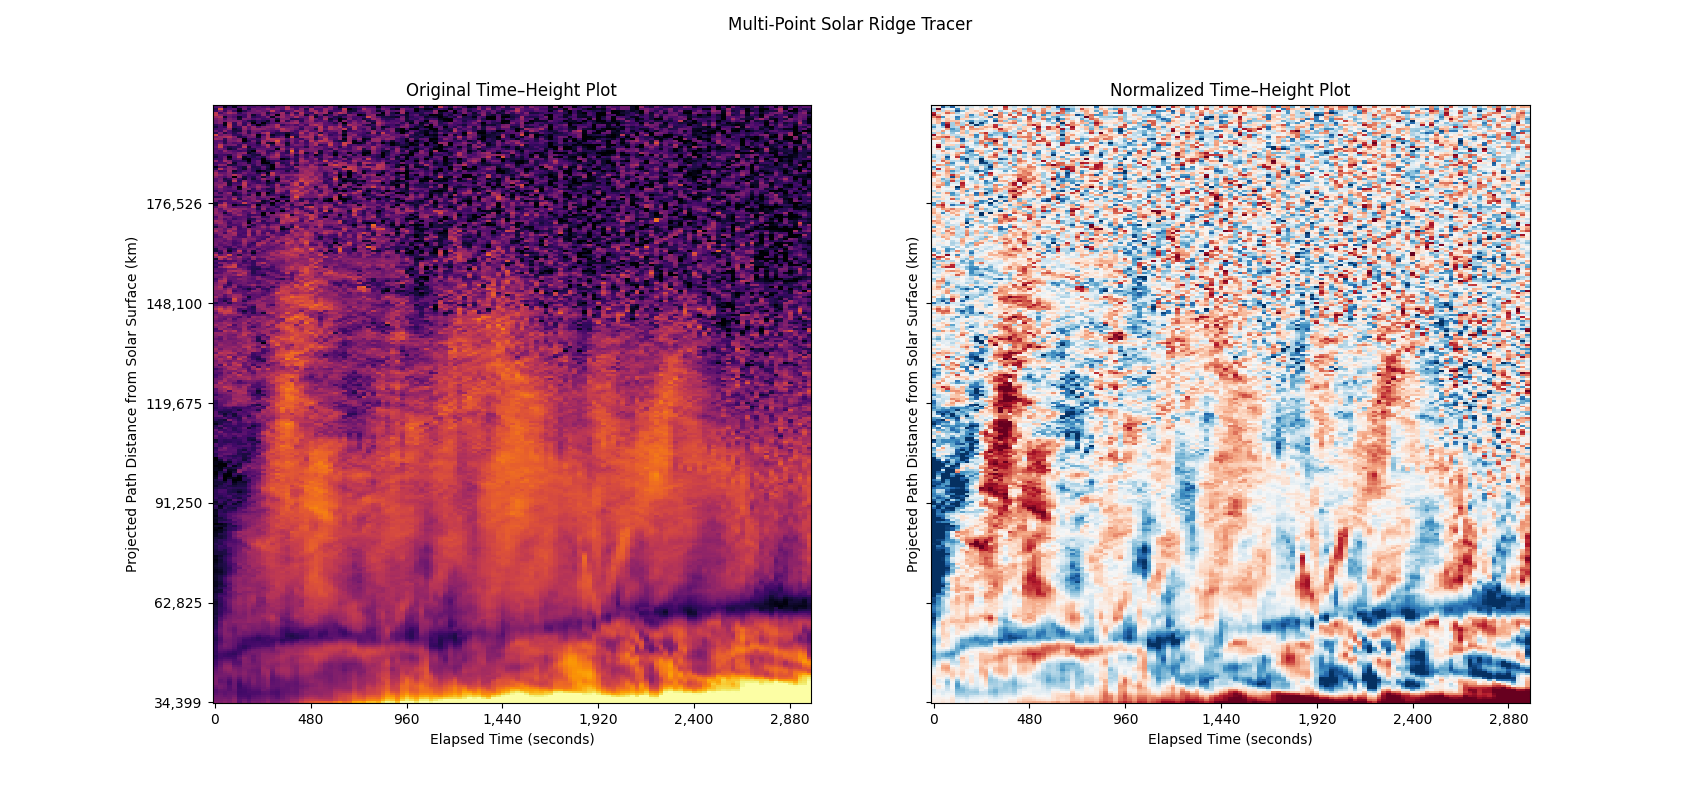

In [11]:
# ============================================================
# STEP 7 — LAUNCH DUAL RIDGE TRACER
# ============================================================

tracer = DualSolarRidgeTracer(
    original_image=original.T,
    normalized_image=normalized.T,
    distance_grid_km=distance_grid_surface,
    cadence_seconds=CADENCE_SECONDS,
    max_step=8,
    corridor=20,
    curvature_weight=0.5,
    slope_weight=0.03,
    ridge_weight=2.0
)

In [12]:

# ============================================================
# CELL 7A — SOLAR RIDGE VELOCITY AND ACCELERATION ANALYSIS
#
# Requires:
#   tracer (from Cell 7)
#
# Uses:
#   scipy.signal.savgol_filter
#   numpy, matplotlib, ipywidgets
#
# Units:
#   Distance: km
#   Time: seconds
#   Velocity: km/s
#   Acceleration: m/s^2
#
# Designed for JupyterLab with %matplotlib widget
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.signal import savgol_filter
from IPython.display import display


class SolarRidgeKinematics:

    def __init__(self, tracer):
        self.tracer = tracer
        self.results = {}
        self.current_figure = None

        if len(tracer.paths) == 0:
            raise ValueError(
                "No traced ridges found. Trace at least "
                "one ridge in Cell 7 before running Cell 7A."
            )

        self._create_interface()

    # ========================================================
    # WINDOW VALIDATION
    # ========================================================

    @staticmethod
    def valid_window(requested, n, polyorder):
        window = int(requested)

        if window % 2 == 0:
            window += 1

        max_window = n if n % 2 else n - 1
        window = min(window, max_window)

        minimum = polyorder + 1
        if minimum % 2 == 0:
            minimum += 1

        if window < minimum:
            raise ValueError(
                f"At least {minimum} samples are needed "
                f"for polynomial order {polyorder}."
            )

        return window

    # ========================================================
    # CALCULATE KINEMATICS
    # ========================================================

    def calculate(
        self,
        ridge_index,
        window_length=11,
        polyorder=3
    ):
        path = self.tracer.paths[ridge_index]

        time_s, distance_km = (
            self.tracer.calibrate_path(path)
        )

        time_s = np.asarray(time_s, dtype=float)
        distance_km = np.asarray(distance_km, dtype=float)

        valid = (
            np.isfinite(time_s)
            & np.isfinite(distance_km)
        )

        time_s = time_s[valid]
        distance_km = distance_km[valid]

        if len(time_s) < 5:
            raise ValueError(
                "At least five ridge samples are required."
            )

        dt_values = np.diff(time_s)

        if not np.allclose(
            dt_values,
            dt_values[0],
            rtol=1e-6,
            atol=1e-8
        ):
            raise ValueError(
                "Ridge samples must be evenly spaced in time."
            )

        dt = float(dt_values[0])

        if dt <= 0:
            raise ValueError(
                "Time values must increase."
            )

        window = self.valid_window(
            window_length,
            len(time_s),
            polyorder
        )

        # ----------------------------------------------------
        # SAVITZKY-GOLAY SMOOTHING
        # ----------------------------------------------------

        smoothed_distance = savgol_filter(
            distance_km,
            window_length=window,
            polyorder=polyorder,
            deriv=0,
            mode="interp"
        )

        # First derivative: km/s
        velocity = savgol_filter(
            distance_km,
            window_length=window,
            polyorder=polyorder,
            deriv=1,
            delta=dt,
            mode="interp"
        )

        # Second derivative: km/s^2 -> m/s^2
        acceleration = 1000.0 * savgol_filter(
            distance_km,
            window_length=window,
            polyorder=polyorder,
            deriv=2,
            delta=dt,
            mode="interp"
        )

        # ----------------------------------------------------
        # GLOBAL LINEAR FIT
        # ----------------------------------------------------

        linear_coeff = np.polyfit(
            time_s,
            distance_km,
            1
        )

        average_velocity = linear_coeff[0]

        # ----------------------------------------------------
        # GLOBAL QUADRATIC FIT
        # ----------------------------------------------------

        centered_time = time_s - time_s[0]

        quadratic_coeff = np.polyfit(
            centered_time,
            distance_km,
            2
        )

        quadratic_distance = np.polyval(
            quadratic_coeff,
            centered_time
        )

        quadratic_acceleration = (
            2.0 * quadratic_coeff[0] * 1000.0
        )

        quadratic_initial_velocity = (
            quadratic_coeff[1]
        )

        # ----------------------------------------------------
        # RESIDUALS
        # ----------------------------------------------------

        residuals = distance_km - smoothed_distance

        residual_rms_km = np.sqrt(
            np.mean(residuals**2)
        )

        result = {
            "ridge_index": ridge_index,
            "time_seconds": time_s,
            "distance_km": distance_km,
            "smoothed_distance_km": smoothed_distance,
            "velocity_km_s": velocity,
            "acceleration_m_s2": acceleration,
            "linear_velocity_km_s": average_velocity,
            "quadratic_distance_km": quadratic_distance,
            "quadratic_acceleration_m_s2": quadratic_acceleration,
            "quadratic_initial_velocity_km_s": quadratic_initial_velocity,
            "residual_rms_km": residual_rms_km,
            "window_length": window,
            "polyorder": polyorder
        }

        self.results[ridge_index] = result

        return result

    # ========================================================
    # PLOT RESULTS
    # ========================================================

    def plot(self, result):
        time_s = result["time_seconds"]

        fig, axes = plt.subplots(
            3, 1,
            figsize=(12, 11),
            sharex=True,
            constrained_layout=True
        )

        # ----------------------------------------------------
        # DISTANCE VS TIME
        # ----------------------------------------------------

        axes[0].plot(
            time_s,
            result["distance_km"],
            ".",
            color="gray",
            markersize=4,
            alpha=0.65,
            label="Traced ridge"
        )

        axes[0].plot(
            time_s,
            result["smoothed_distance_km"],
            color="tab:blue",
            linewidth=2,
            label="Savitzky-Golay smoothing"
        )

        axes[0].plot(
            time_s,
            result["quadratic_distance_km"],
            "--",
            color="tab:orange",
            linewidth=1.8,
            label="Constant-acceleration fit"
        )

        axes[0].set_ylabel(
            "Projected Distance (km)"
        )

        axes[0].set_title(
            "Distance vs. Time"
        )

        axes[0].legend()
        axes[0].grid(alpha=0.25)

        # ----------------------------------------------------
        # VELOCITY VS TIME
        # ----------------------------------------------------

        axes[1].plot(
            time_s,
            result["velocity_km_s"],
            color="tab:green",
            linewidth=2,
            label="Local velocity"
        )

        axes[1].axhline(
            result["linear_velocity_km_s"],
            color="tab:red",
            linestyle="--",
            label="Global linear-fit velocity"
        )

        axes[1].set_ylabel(
            "Projected Velocity (km/s)"
        )

        axes[1].set_title(
            "Velocity vs. Time"
        )

        axes[1].legend()
        axes[1].grid(alpha=0.25)

        # ----------------------------------------------------
        # ACCELERATION VS TIME
        # ----------------------------------------------------

        axes[2].plot(
            time_s,
            result["acceleration_m_s2"],
            color="tab:purple",
            linewidth=2,
            label="Local acceleration"
        )

        axes[2].axhline(
            result["quadratic_acceleration_m_s2"],
            color="tab:orange",
            linestyle="--",
            label="Global quadratic-fit acceleration"
        )

        axes[2].axhline(
            0,
            color="gray",
            linewidth=0.8
        )

        axes[2].set_ylabel(
            "Projected Acceleration (m/s²)"
        )

        axes[2].set_xlabel(
            "Elapsed Time (seconds)"
        )

        axes[2].set_title(
            "Acceleration vs. Time"
        )

        axes[2].legend()
        axes[2].grid(alpha=0.25)

        fig.suptitle(
            f"Ridge {result['ridge_index'] + 1} — "
            "Kinematic Analysis",
            fontsize=14
        )

        # Do not call plt.show() here.
        # The figure will be displayed explicitly inside
        # the widgets.Output() area.

        return fig

    # ========================================================
    # NUMERICAL SUMMARY
    # ========================================================

    def summarize(self, result):
        velocity = result["velocity_km_s"]
        acceleration = result["acceleration_m_s2"]

        print("=" * 60)
        print(
            f"RIDGE {result['ridge_index'] + 1} "
            "KINEMATIC SUMMARY"
        )
        print("=" * 60)

        print(
            f"Smoothing window: "
            f"{result['window_length']} frames"
        )

        print(
            f"Polynomial order: "
            f"{result['polyorder']}"
        )

        window_duration = (
            (result["window_length"] - 1)
            * self.tracer.cadence
        )

        print(
            f"Window duration: "
            f"{window_duration:.0f} seconds"
        )

        print()
        print(
            f"Linear-fit velocity: "
            f"{result['linear_velocity_km_s']:.2f} km/s"
        )

        print(
            f"Median local velocity: "
            f"{np.median(velocity):.2f} km/s"
        )

        print(
            f"Minimum local velocity: "
            f"{np.min(velocity):.2f} km/s"
        )

        print(
            f"Maximum local velocity: "
            f"{np.max(velocity):.2f} km/s"
        )

        print()
        print(
            f"Global quadratic acceleration: "
            f"{result['quadratic_acceleration_m_s2']:.2f} m/s²"
        )

        print(
            f"Median local acceleration: "
            f"{np.median(acceleration):.2f} m/s²"
        )

        print(
            f"Minimum local acceleration: "
            f"{np.min(acceleration):.2f} m/s²"
        )

        print(
            f"Maximum local acceleration: "
            f"{np.max(acceleration):.2f} m/s²"
        )

        print()
        print(
            f"Distance smoothing residual RMS: "
            f"{result['residual_rms_km']:.2f} km"
        )

        print("=" * 60)

    # ========================================================
    # INTERACTIVE INTERFACE
    # ========================================================

    def _create_interface(self):
        self.ridge_selector = widgets.Dropdown(
            options=[
                (f"Ridge {i + 1}", i)
                for i in range(len(self.tracer.paths))
            ],
            value=0,
            description="Ridge"
        )

        self.window_slider = widgets.IntSlider(
            value=11,
            min=5,
            max=51,
            step=2,
            description="Window",
            continuous_update=False
        )

        self.poly_selector = widgets.Dropdown(
            options=[2, 3, 4, 5],
            value=3,
            description="Poly order"
        )

        self.analyze_button = widgets.Button(
            description="Analyze Ridge",
            button_style="success"
        )

        self.save_button = widgets.Button(
            description="Save Analysis",
            button_style="info"
        )

        self.status = widgets.HTML(
            "Choose a ridge and smoothing settings."
        )

        # Dedicated area for figures and printed results
        self.output = widgets.Output()

        # Connect buttons
        self.analyze_button.on_click(
            self._on_analyze
        )

        self.save_button.on_click(
            self._on_save
        )

        # Display controls and output area
        display(
            widgets.VBox([
                widgets.HBox([
                    self.ridge_selector,
                    self.window_slider,
                    self.poly_selector
                ]),
                widgets.HBox([
                    self.analyze_button,
                    self.save_button
                ]),
                self.status,
                self.output
            ])
        )

    # ========================================================
    # ANALYZE BUTTON CALLBACK
    # ========================================================

    def _on_analyze(self, button):
        try:
            result = self.calculate(
                ridge_index=self.ridge_selector.value,
                window_length=self.window_slider.value,
                polyorder=self.poly_selector.value
            )

            # Close previous figure to avoid accumulating
            # multiple open Matplotlib figures.
            if self.current_figure is not None:
                plt.close(self.current_figure)

            # Clear previous output
            self.output.clear_output(wait=True)

            with self.output:
                fig = self.plot(result)

                self.current_figure = fig

                # Explicitly display the ipympl canvas
                display(fig.canvas)

                # Print numerical results beneath the plot
                self.summarize(result)

            self.status.value = (
                "Analysis complete. "
                "Plots and numerical results are shown below."
            )

        except Exception as exc:
            self.status.value = (
                f"Analysis error: {exc}"
            )

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    def save(
        self,
        filename="solar_ridge_kinematics.npz"
    ):
        if not self.results:
            raise ValueError(
                "No analyses available. "
                "Click Analyze Ridge first."
            )

        data = {}

        for ridge_index, result in self.results.items():
            prefix = f"ridge_{ridge_index}"

            for key, value in result.items():
                if key != "ridge_index":
                    data[f"{prefix}_{key}"] = value

        np.savez_compressed(
            filename,
            **data
        )

        print(f"Saved {filename}")

    # ========================================================
    # SAVE BUTTON CALLBACK
    # ========================================================

    def _on_save(self, button):
        try:
            with self.output:
                self.save()

            self.status.value = (
                "Kinematic analysis saved successfully."
            )

        except Exception as exc:
            self.status.value = (
                f"Save error: {exc}"
            )


# ============================================================
# LAUNCH KINEMATIC ANALYSIS
# ============================================================

kinematics = SolarRidgeKinematics(tracer)


In [21]:
print("Analyzed ridges:", list(kinematics.results.keys()))

result = kinematics.results[0]
kinematics.summarize(result)

Analyzed ridges: [0, 1, 2, 3, 4]
RIDGE 1 KINEMATIC SUMMARY
Smoothing window: 9 frames
Polynomial order: 3
Window duration: 216 s

Linear-fit velocity: 328.07 km/s
Median local velocity: 349.01 km/s
Minimum local velocity: -128.09 km/s
Maximum local velocity: 655.76 km/s

Global quadratic acceleration: 4082.54 m/s²
Median local acceleration: 4082.54 m/s²
Minimum local acceleration: 2307.96 m/s²
Maximum local acceleration: 5857.12 m/s²

Distance smoothing residual RMS: 1216.61 km


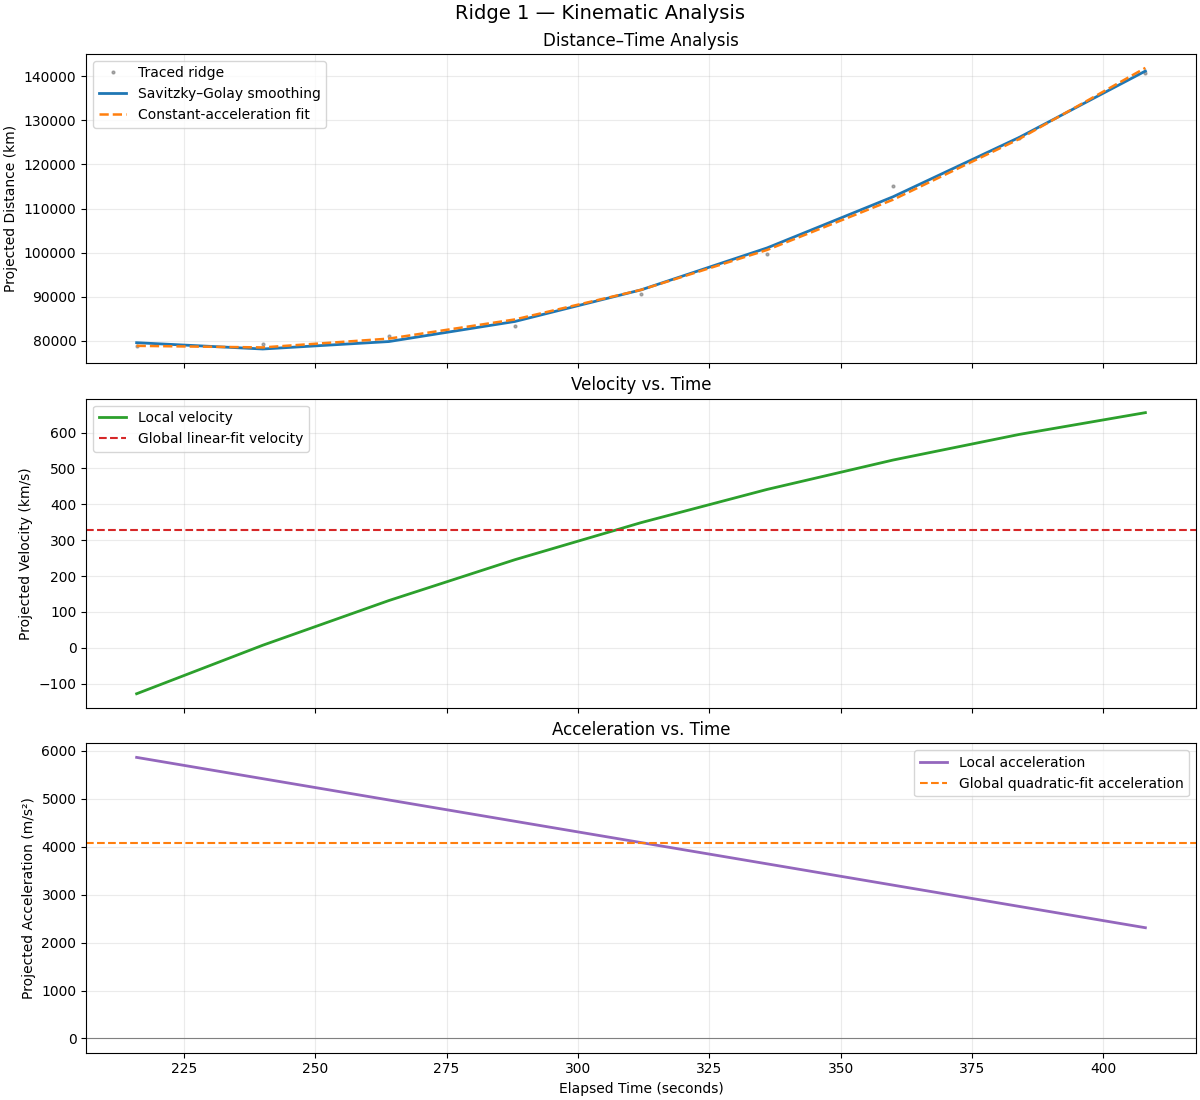

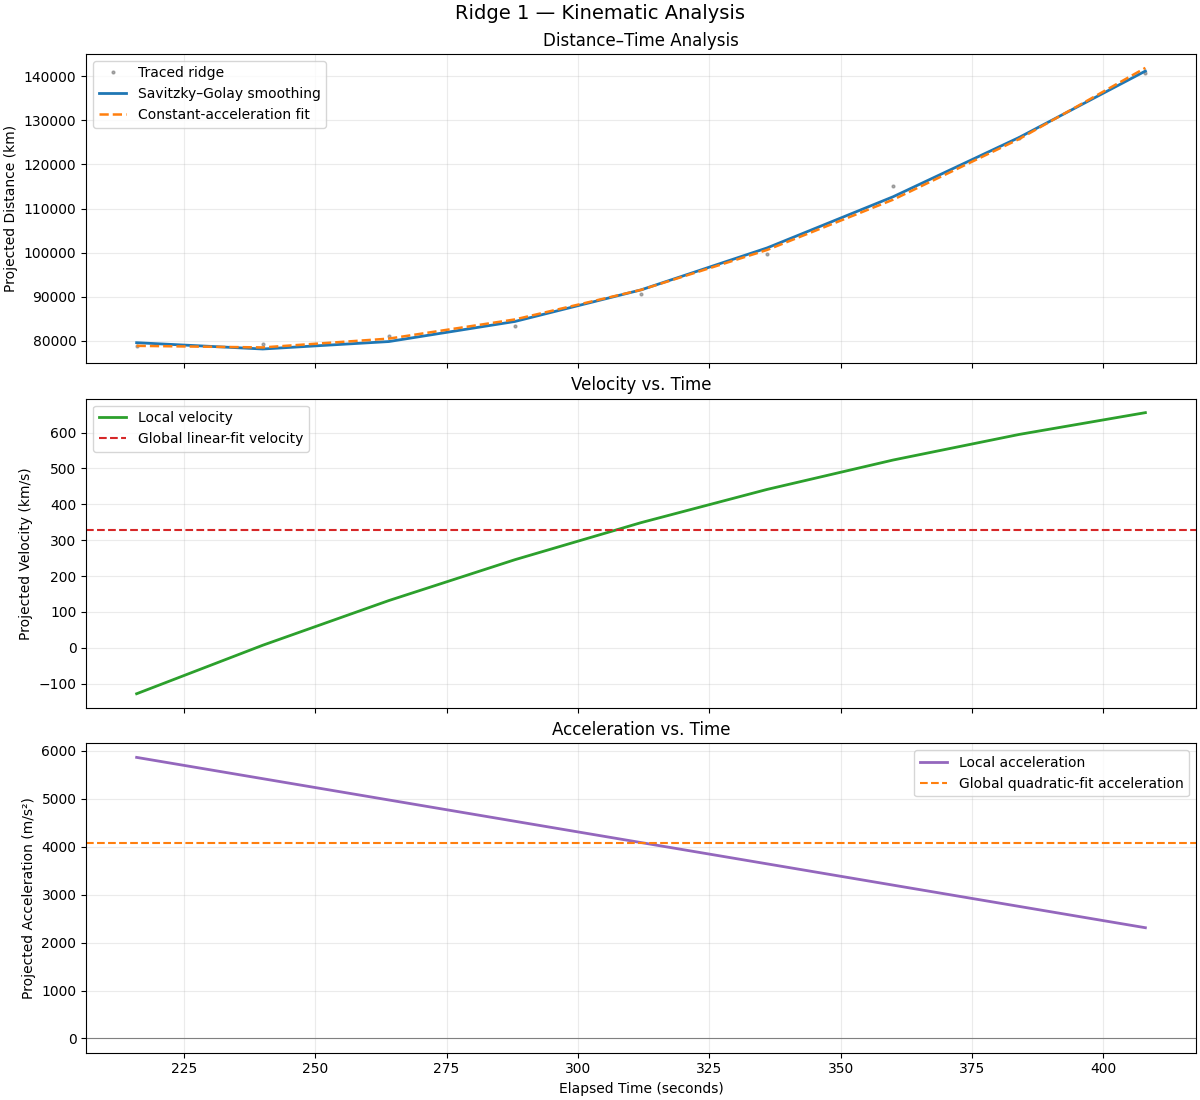

In [24]:
result = kinematics.results[0]
fig = kinematics.plot(result)
display(fig.canvas)

In [13]:
plt.close('all')

In [ ]:
np.savez_compressed(
    "solar_eruption_analysis.npz",

    # Calibration
    cadence_seconds=CADENCE_SECONDS,
    solar_km_per_pixel=SOLAR_KM_PER_PIXEL,
    ridge_km_per_pixel=ridge_km_per_pixel,
    solar_surface_point=SOLAR_SURFACE_POINT,

    # Coordinates
    time_seconds=time_seconds,
    distance_grid_surface_km=distance_grid_surface,
    surface_offsets_km=surface_offsets_km,

    # Paths
    all_paths=all_paths,
    all_distances_km=all_distances,
    all_distances_surface_km=all_distances_surface,
    curve_lengths_km=curve_lengths_km,

    # Time-height images
    time_distance_km=time_distance_km,
    sheet_cube=sheet_cube,
    original=original,
    background_subtracted=background_subtracted,
    running_difference=running_difference,
    normalized=normalized,
    percentage_variation=percentage_variation,

    # Settings
    enhancement_method=ENHANCEMENT_METHOD,
    flare_cutoff_x=FLARE_CUTOFF_X
)

print("Saved solar_eruption_analysis.npz")

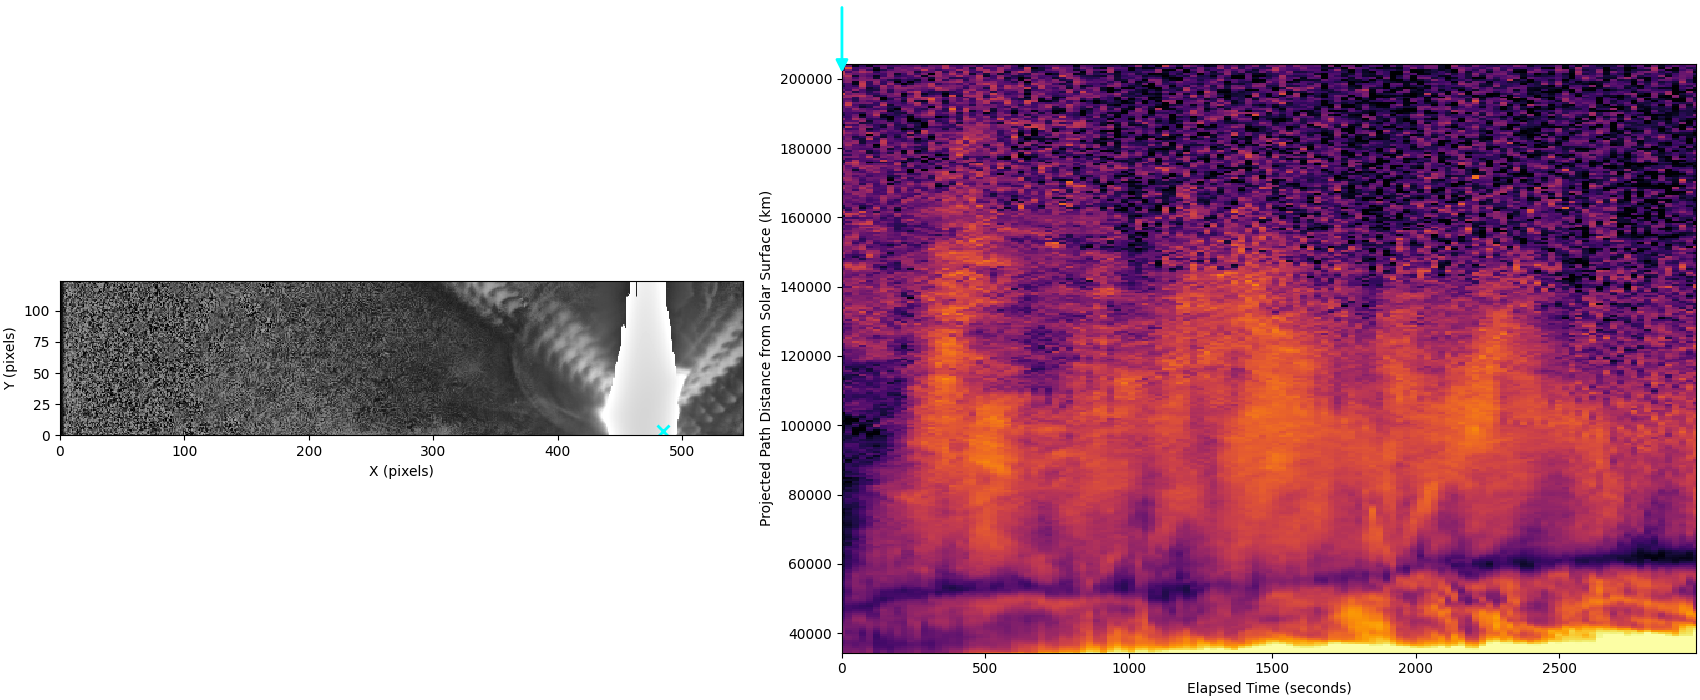

In [14]:

# ============================================================
# CELL 9 — SYNCHRONIZED ANIMATION
# ============================================================

class SolarTimeHeightAnimation:

    def __init__(
        self,
        image_data,
        paths,
        original_td,
        normalized_td,
        distance_grid_km,
        cadence_seconds=24.0,
        solar_surface_point=(485, 3),
        figsize=(17, 7)
    ):
        self.images = np.asarray(image_data, dtype=float)
        self.paths = np.asarray(paths, dtype=float)

        self.original_td = np.asarray(
            original_td, dtype=float
        )
        self.normalized_td = np.asarray(
            normalized_td, dtype=float
        )

        self.distance_grid = np.asarray(
            distance_grid_km, dtype=float
        )

        self.cadence = float(cadence_seconds)
        self.surface_point = solar_surface_point

        self.n_frames = self.images.shape[0]

        if self.paths.shape[0] != self.n_frames:
            raise ValueError("Path frame count mismatch.")

        if (
            self.original_td.shape != self.normalized_td.shape
            or self.original_td.shape[0] != self.n_frames
            or self.original_td.shape[1] != len(self.distance_grid)
        ):
            raise ValueError(
                "Time-height data dimensions do not match."
            )

        self.time_axis = (
            np.arange(self.n_frames) * self.cadence
        )

        self.fig, (self.ax_solar, self.ax_td) = plt.subplots(
            1, 2,
            figsize=figsize,
            gridspec_kw={
                "width_ratios": [1, 1.25]
            },
            constrained_layout=True
        )

        # ----------------------------------------------------
        # LEFT: SOLAR IMAGE
        # ----------------------------------------------------

        finite = self.images[np.isfinite(self.images)]

        solar_low, solar_high = np.percentile(
            finite, [2, 99.5]
        )

        self.im_solar = self.ax_solar.imshow(
            self.images[0].T,
            origin="lower",
            cmap="gray",
            vmin=solar_low,
            vmax=solar_high,
            interpolation="nearest"
        )

        self.path_line, = self.ax_solar.plot(
            [],
            [],
            color="red",
            linewidth=2
        )

        self.ax_solar.plot(
            self.surface_point[0],
            self.surface_point[1],
            marker="x",
            color="cyan",
            markersize=9,
            markeredgewidth=2,
            linestyle="None"
        )

        self.ax_solar.set_xlabel("X (pixels)")
        self.ax_solar.set_ylabel("Y (pixels)")

        self.ax_solar.set_xlim(
            0, self.images.shape[1] - 1
        )
        self.ax_solar.set_ylim(
            0, self.images.shape[2] - 1
        )

        # ----------------------------------------------------
        # RIGHT: TIME-HEIGHT IMAGE
        # ----------------------------------------------------

        self.td_extent = calibrated_extent(
            self.distance_grid,
            self.time_axis
        )

        finite_td = self.original_td[
            np.isfinite(self.original_td)
        ]

        td_low, td_high = np.percentile(
            finite_td, [2, 99]
        )

        if td_high <= td_low:
            td_high = td_low + 1

        self.im_td = self.ax_td.imshow(
            self.original_td.T,
            origin="lower",
            aspect="auto",
            extent=self.td_extent,
            cmap="inferno",
            vmin=td_low,
            vmax=td_high,
            interpolation="nearest"
        )

        self.ax_td.set_xlabel(
            "Elapsed Time (seconds)"
        )
        self.ax_td.set_ylabel(
            "Projected Path Distance from Solar Surface (km)"
        )

        self.ax_td.set_xlim(
            self.time_axis[0],
            self.time_axis[-1]
        )

        self.ax_td.set_ylim(
            self.distance_grid[0],
            self.distance_grid[-1]
        )

        # Current time column indicator
        self.time_line = self.ax_td.axvline(
            self.time_axis[0],
            color="cyan",
            linewidth=1.5,
            linestyle="--",
            alpha=0.9
        )

        # Arrow is positioned using x=data coordinates
        # and y=axes-fraction coordinates.
        # This keeps it visible when zooming vertically.
        self.time_arrow = self.ax_td.annotate(
            "",
            xy=(self.time_axis[0], 0.98),
            xycoords=self.ax_td.get_xaxis_transform(),
            xytext=(self.time_axis[0], 1.10),
            textcoords=self.ax_td.get_xaxis_transform(),
            arrowprops=dict(
                arrowstyle="-|>",
                color="cyan",
                linewidth=2,
                mutation_scale=18
            ),
            annotation_clip=False
        )

        # ----------------------------------------------------
        # CONTROLS
        # ----------------------------------------------------

        self.play = widgets.Play(
            value=0,
            min=0,
            max=self.n_frames - 1,
            step=1,
            interval=150
        )

        self.frame_slider = widgets.IntSlider(
            value=0,
            min=0,
            max=self.n_frames - 1,
            step=1,
            description="Frame",
            continuous_update=True,
            layout=widgets.Layout(width="500px")
        )

        widgets.jslink(
            (self.play, "value"),
            (self.frame_slider, "value")
        )

        self.speed = widgets.IntSlider(
            value=150,
            min=50,
            max=1000,
            step=25,
            description="ms/frame"
        )

        self.display_mode = widgets.Dropdown(
            options=[
                "Original",
                "Normalized"
            ],
            value="Original",
            description="Time-height"
        )

        self.show_path = widgets.Checkbox(
            value=True,
            description="Show fitted curve"
        )

        self.show_indicator = widgets.Checkbox(
            value=True,
            description="Show time indicator"
        )

        self.frame_label = widgets.HTML()

        self.frame_slider.observe(
            self.update_frame,
            names="value"
        )

        self.speed.observe(
            lambda change: setattr(
                self.play,
                "interval",
                change["new"]
            ),
            names="value"
        )

        self.display_mode.observe(
            self.update_time_height,
            names="value"
        )

        self.show_path.observe(
            self.update_frame,
            names="value"
        )

        self.show_indicator.observe(
            self.update_frame,
            names="value"
        )

        controls = widgets.VBox([
            widgets.HBox([
                self.play,
                self.frame_slider
            ]),
            widgets.HBox([
                self.speed,
                self.display_mode
            ]),
            widgets.HBox([
                self.show_path,
                self.show_indicator
            ]),
            self.frame_label
        ])

        display(controls)
        plt.show()

        self.update_frame()

    def update_time_height(self, change=None):
        mode = self.display_mode.value

        if mode == "Original":
            data = self.original_td
            cmap = "inferno"

            finite = data[np.isfinite(data)]

            low, high = np.percentile(
                finite, [2, 99]
            )

            if high <= low:
                high = low + 1

        else:
            data = self.normalized_td
            cmap = "RdBu_r"

            finite = data[np.isfinite(data)]

            limit = max(
                np.percentile(
                    np.abs(finite), 98
                ),
                1e-10
            )

            low, high = -limit, limit

        self.im_td.set_data(data.T)
        self.im_td.set_cmap(cmap)
        self.im_td.set_clim(low, high)

        self.ax_td.set_title(
            f"{mode} Time–Height Plot"
        )

        self.fig.canvas.draw_idle()

    def update_frame(self, change=None):
        frame = self.frame_slider.value
        time_s = self.time_axis[frame]

        # Update solar image
        self.im_solar.set_data(
            self.images[frame].T
        )

        # Update fitted path
        if self.show_path.value:
            path = self.paths[frame]

            self.path_line.set_data(
                path[:, 0],
                path[:, 1]
            )
            self.path_line.set_visible(True)
        else:
            self.path_line.set_visible(False)

        # Move the vertical line and arrow
        self.time_line.set_xdata(
            [time_s, time_s]
        )

        self.time_arrow.xy = (time_s, 0.98)
        self.time_arrow.set_position(
            (time_s, 1.10)
        )

        self.time_line.set_visible(
            self.show_indicator.value
        )

        self.time_arrow.set_visible(
            self.show_indicator.value
        )

        self.ax_solar.set_title(
            f"Solar Image — Frame {frame}"
        )

        self.ax_td.set_title(
            f"{self.display_mode.value} Time–Height Plot"
        )

        self.frame_label.value = (
            f"<b>Frame:</b> {frame} &nbsp; "
            f"<b>Elapsed time:</b> {time_s:.0f} s "
            f"({time_s / 60:.2f} min)"
        )

        self.fig.canvas.draw_idle()


# ============================================================
# LAUNCH ANIMATION
# ============================================================

animation = SolarTimeHeightAnimation(
    image_data=image_data,
    paths=all_paths,
    original_td=original,
    normalized_td=normalized,
    distance_grid_km=distance_grid_surface,
    cadence_seconds=CADENCE_SECONDS,
    solar_surface_point=SOLAR_SURFACE_POINT
)
